<a href="https://colab.research.google.com/github/hasanjim-dev/ml-learning/blob/main/hierarchical-dbscan/hierarchical_dbscan_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries import

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

make Blob data

In [3]:

X_blob, y_blob = make_blobs(n_samples=300, centers=4, cluster_std=1.0, random_state=42)

In [5]:
print(X_blob.shape)
print(y_blob.shape)

(300, 2)
(300,)


In [6]:
X_blob

array([[ -9.29768866,   6.47367855],
       [ -9.69874112,   6.93896737],
       [ -1.68665271,   7.79344248],
       [ -7.09730839,  -5.78133274],
       [-10.87645229,   6.3154366 ],
       [ -6.02196757,  -7.04004812],
       [  4.81305976,   2.35848706],
       [ -6.46669574,  -7.44383415],
       [ -2.98837186,   8.82862715],
       [  3.44857534,   2.62972329],
       [ -3.11090424,  10.86656431],
       [  4.99689432,   1.28026009],
       [ -2.30033403,   7.054616  ],
       [ -3.92456837,   8.59364081],
       [ -9.48897033,   6.83639753],
       [ -3.21125072,   8.68662398],
       [-10.46587019,   7.37160786],
       [  2.61473625,   2.159624  ],
       [ -2.41212007,   9.98293112],
       [ -1.92234053,  11.20474175],
       [  5.79847442,   1.15248737],
       [ -2.67048333,   9.41833699],
       [ -5.90450746,  -7.02716697],
       [ -8.95065581,   7.10255332],
       [ -2.97261532,   8.54855637],
       [ -8.30852358,   8.76509154],
       [ -9.41509909,   8.07891414],
 

In [7]:
y_blob

array([3, 3, 0, 2, 3, 2, 1, 2, 0, 1, 0, 1, 0, 0, 3, 0, 3, 1, 0, 0, 1, 0,
       2, 3, 0, 3, 3, 2, 2, 1, 0, 1, 3, 1, 3, 0, 3, 2, 3, 2, 1, 0, 3, 2,
       0, 0, 3, 1, 3, 1, 2, 3, 2, 0, 2, 1, 3, 1, 1, 0, 3, 1, 1, 3, 2, 2,
       2, 2, 2, 0, 2, 2, 3, 1, 0, 3, 2, 2, 0, 2, 0, 0, 3, 0, 2, 3, 3, 1,
       1, 1, 3, 0, 3, 0, 0, 3, 2, 0, 3, 3, 1, 1, 1, 0, 0, 0, 0, 0, 2, 3,
       1, 0, 0, 0, 0, 1, 3, 2, 3, 2, 2, 2, 0, 3, 2, 3, 3, 0, 3, 2, 1, 0,
       0, 0, 0, 1, 1, 3, 0, 2, 0, 1, 2, 0, 1, 1, 1, 1, 2, 0, 0, 3, 1, 2,
       0, 1, 2, 3, 3, 1, 0, 3, 2, 3, 1, 3, 2, 0, 0, 0, 0, 0, 2, 1, 1, 2,
       2, 1, 1, 2, 3, 0, 3, 1, 1, 3, 2, 0, 1, 1, 2, 2, 2, 3, 1, 2, 2, 1,
       1, 3, 0, 0, 2, 1, 0, 2, 2, 3, 2, 0, 0, 2, 2, 1, 3, 2, 3, 3, 0, 3,
       3, 2, 3, 2, 1, 1, 3, 3, 1, 1, 1, 3, 0, 2, 1, 2, 3, 1, 3, 3, 3, 2,
       2, 1, 3, 2, 2, 2, 3, 2, 3, 2, 3, 1, 2, 3, 1, 0, 3, 0, 1, 0, 3, 0,
       2, 1, 2, 1, 1, 0, 0, 2, 1, 1, 3, 3, 2, 0, 0, 1, 1, 1, 1, 2, 3, 1,
       2, 1, 1, 2, 0, 2, 1, 0, 3, 0, 1, 0, 3, 3])

Making Moon data

In [10]:

X_moon, y_moon = make_moons(n_samples=300, noise=0.05, random_state=42)

Data scale

In [11]:

scaler = StandardScaler()
X_moon_scaled = scaler.fit_transform(X_moon)

Data plot

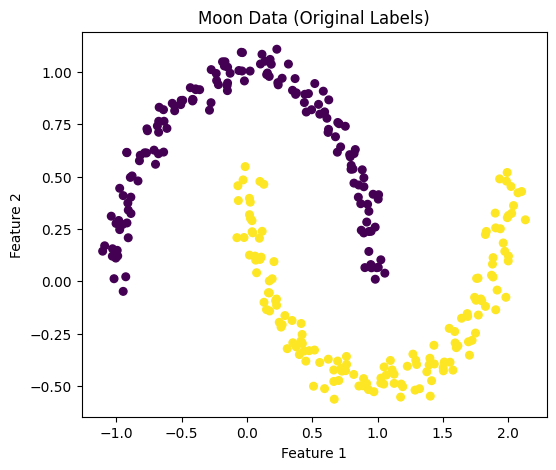

In [12]:
plt.figure(figsize=(6, 5))
plt.scatter(X_moon[:, 0], X_moon[:, 1], c=y_moon, cmap='viridis', s=30)
plt.title("Moon Data (Original Labels)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Blob data plot

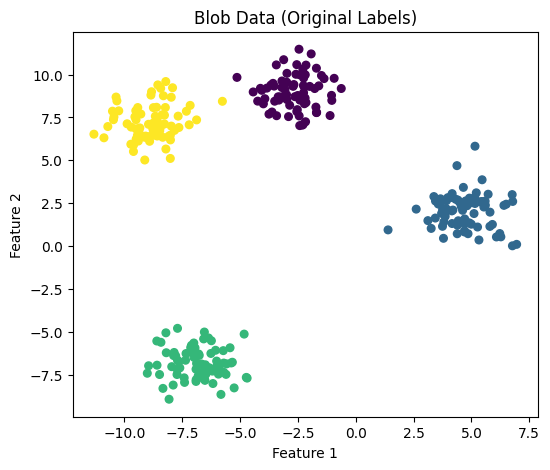

In [13]:
plt.figure(figsize=(6, 5))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap='viridis', s=30)
plt.title("Blob Data (Original Labels)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

By Seaborn

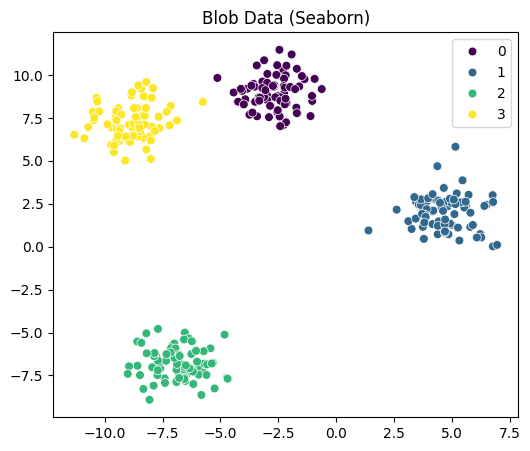

In [14]:
plt.figure(figsize=(6, 5))
sns.scatterplot(x=X_blob[:, 0], y=X_blob[:, 1], hue=y_blob, palette='viridis', s=40)
plt.title("Blob Data (Seaborn)")
plt.show()

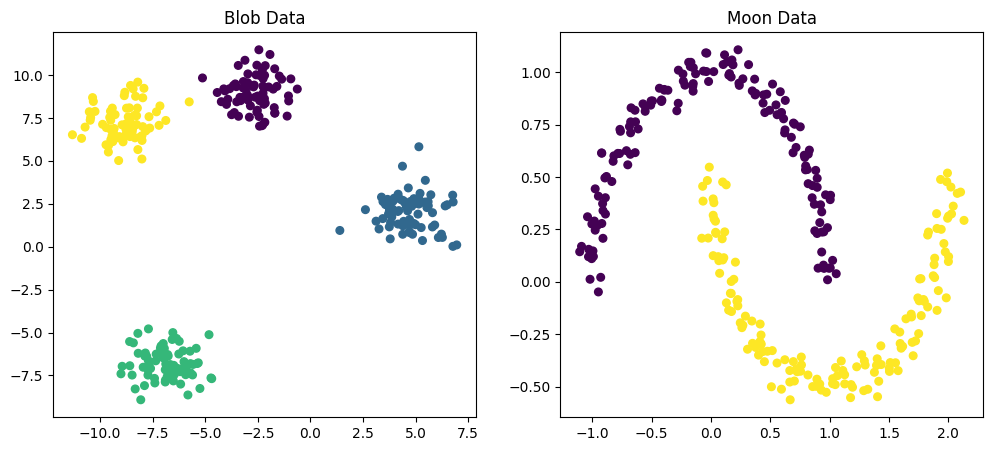

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap='viridis', s=30)
axes[0].set_title("Blob Data")

axes[1].scatter(X_moon[:, 0], X_moon[:, 1], c=y_moon, cmap='viridis', s=30)
axes[1].set_title("Moon Data")

plt.show()

Blob data-in KMeans

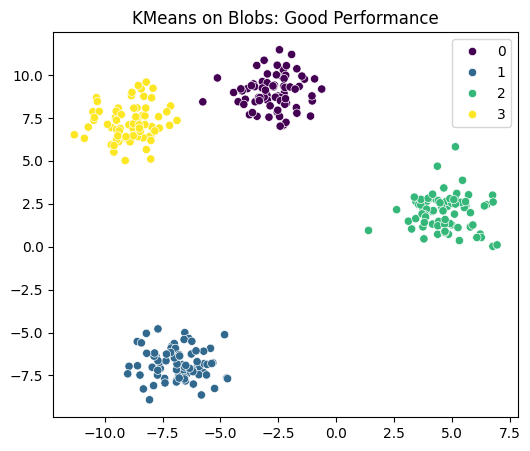

In [16]:
# KMeans on Blobs
Xb_scaled = StandardScaler().fit_transform(X_blob)
kmeans_blob = KMeans(n_clusters=4, random_state=42)  # We know there are 4 clusters in the blob data
kmeans_blob_labels = kmeans_blob.fit_predict(Xb_scaled)

plt.figure(figsize=(6, 5))
sns.scatterplot(x=X_blob[:, 0], y=X_blob[:, 1], hue=kmeans_blob_labels, palette='viridis')
plt.title("KMeans on Blobs: Good Performance")
plt.show()

Moon data-in KMeans

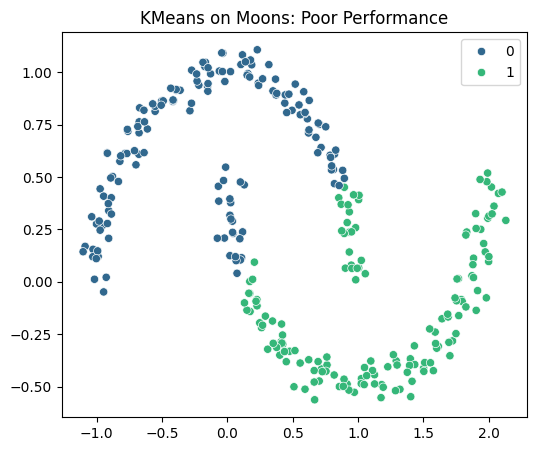

In [17]:

Xm_scaled = StandardScaler().fit_transform(X_moon)
kmeans_moon = KMeans(n_clusters=2, random_state=42)  # moon data-তে 2টা cluster আছে
kmeans_moon_labels = kmeans_moon.fit_predict(Xm_scaled)

plt.figure(figsize=(6, 5))
sns.scatterplot(x=X_moon[:, 0], y=X_moon[:, 1], hue=kmeans_moon_labels, palette='viridis')
plt.title("KMeans on Moons: Poor Performance")
plt.show()

label-difference

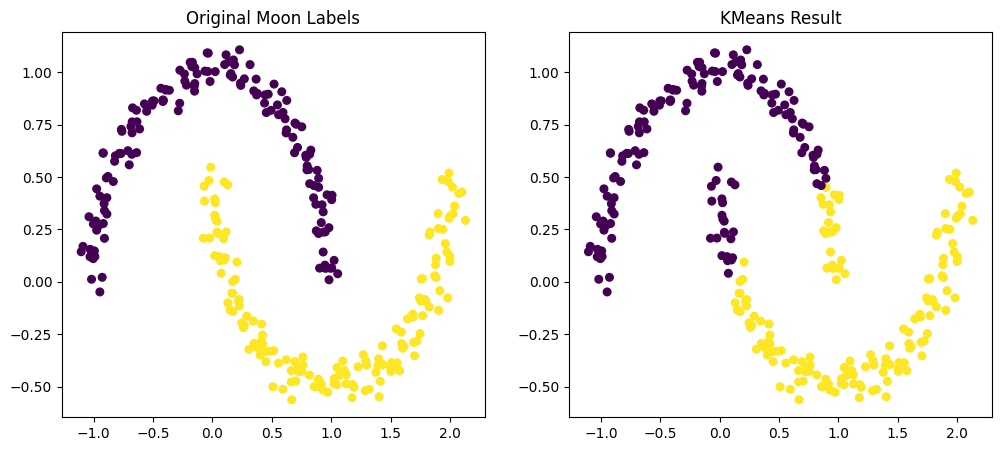

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_moon[:, 0], X_moon[:, 1], c=y_moon, cmap='viridis', s=30)
axes[0].set_title("Original Moon Labels")

axes[1].scatter(X_moon[:, 0], X_moon[:, 1], c=kmeans_moon_labels, cmap='viridis', s=30)
axes[1].set_title("KMeans Result")

plt.show()

Blob data-Hierarchical Clustering (linkage making)

In [20]:

Xb_scaled = StandardScaler().fit_transform(X_blob)
linked = linkage(Xb_scaled, method='ward')

Dendrogram plot

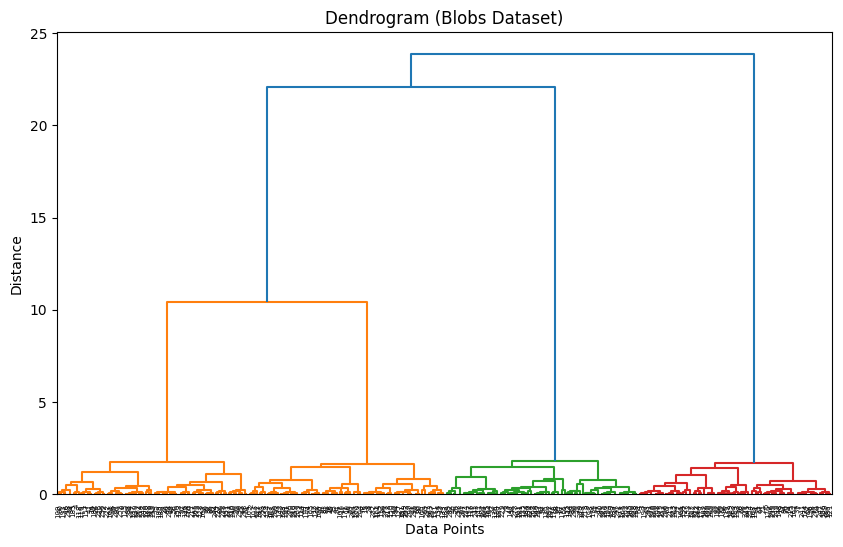

In [22]:

plt.figure(figsize=(10, 6))
dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=False)
plt.title('Dendrogram (Blobs Dataset)')
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()

DBSCAN fit

In [23]:

db = DBSCAN(eps=0.3, min_samples=5)
db_labels = db.fit_predict(Xm_scaled)

DBSCAN result plot

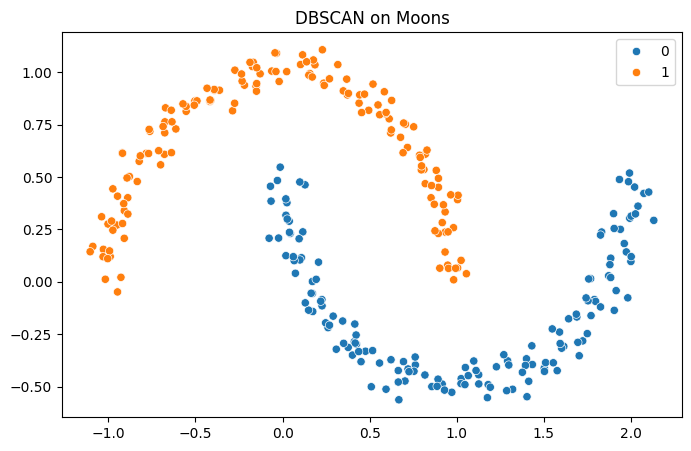

In [25]:

plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_moon[:, 0], y=X_moon[:, 1], hue=db_labels, palette='tab10')
plt.title('DBSCAN on Moons')
plt.show()

In [26]:
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = list(db_labels).count(-1)
print("Clusters:", n_clusters)
print("Noise points:", n_noise)

Clusters: 2
Noise points: 0


For good result eps change

In [27]:
for eps in [0.2, 0.3, 0.4, 0.5]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(Xm_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    print(f"eps={eps}: clusters={n_clusters}, noise={n_noise}")

eps=0.2: clusters=2, noise=2
eps=0.3: clusters=2, noise=0
eps=0.4: clusters=2, noise=0
eps=0.5: clusters=2, noise=0


eps k-distance plot

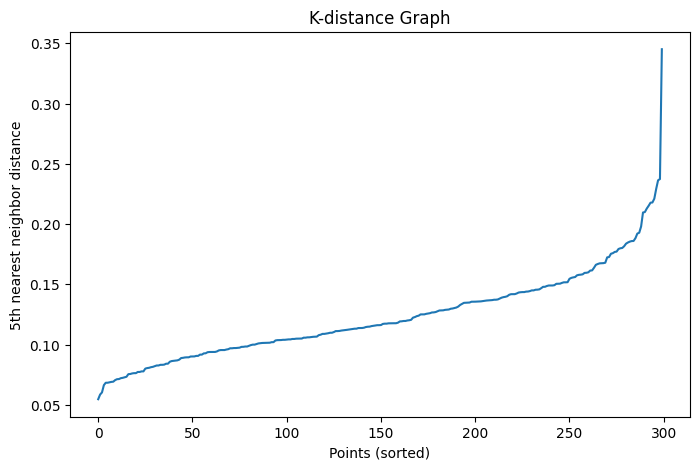

In [28]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(Xm_scaled)
distances, indices = neighbors_fit.kneighbors(Xm_scaled)

distances = np.sort(distances[:, 4])  # 5th nearest neighbor distance

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-distance Graph')
plt.xlabel('Points (sorted)')
plt.ylabel('5th nearest neighbor distance')
plt.show()

Moon data- Hierarchical (single linkage)

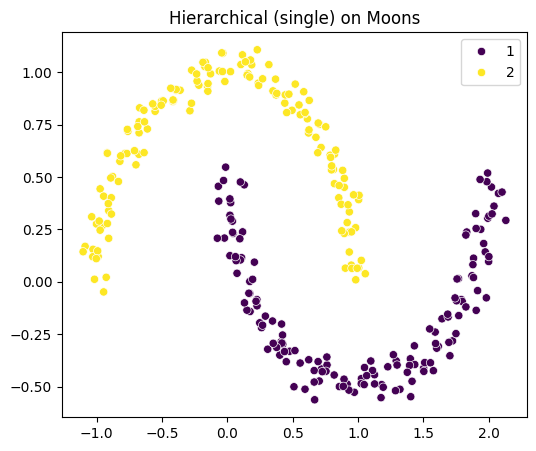

In [29]:
linked_moon = linkage(Xm_scaled, method='single')
hier_moon_labels = fcluster(linked_moon, t=2, criterion='maxclust')

plt.figure(figsize=(6, 5))
sns.scatterplot(x=X_moon[:, 0], y=X_moon[:, 1], hue=hier_moon_labels, palette='viridis')
plt.title("Hierarchical (single) on Moons")
plt.show()

Blob data-DBSCAN

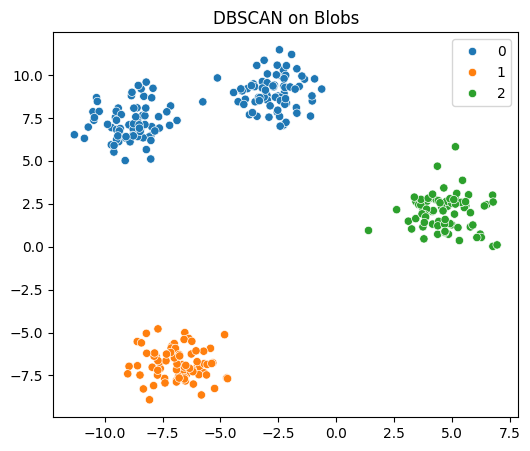

In [30]:
db_blob = DBSCAN(eps=0.5, min_samples=5)
db_blob_labels = db_blob.fit_predict(Xb_scaled)

plt.figure(figsize=(6, 5))
sns.scatterplot(x=X_blob[:, 0], y=X_blob[:, 1], hue=db_blob_labels, palette='tab10')
plt.title("DBSCAN on Blobs")
plt.show()

Silhouette score for Verification of quality

In [32]:
from sklearn.metrics import silhouette_score

hier_labels = fcluster(linked, t=4, criterion='maxclust')

print("KMeans on blobs:", silhouette_score(Xb_scaled, kmeans_blob_labels))
print("Hierarchical on blobs:", silhouette_score(Xb_scaled, hier_labels))

KMeans on blobs: 0.7974739889632732
Hierarchical on blobs: 0.7974739889632732


In [33]:
mask = db_labels != -1
print("DBSCAN on moons:", silhouette_score(Xm_scaled[mask], db_labels[mask]))

DBSCAN on moons: 0.38602599723729836
